<a href="https://colab.research.google.com/github/Melissa-Etes/regressao_boosting/blob/main/Regressao_XGBoost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ciencia de dados para precificar carros usados

Pegando os Dados

In [1]:
import pandas as pd

In [2]:
url = "https://raw.githubusercontent.com/Melissa-Etes/regressao_boosting/refs/heads/main/dados_automoveis.csv"

In [3]:
df = pd.read_csv(url)

In [4]:
df.head()

,Marca,Modelo,Ano,Tipo_combustivel,Potencia_motor,Cilindros_motor,Tipo_transmissao,Rodas_motrizes,Numero_portas,Tamanho,Estilo,Consumo_estrada_milhas,Consumo_cidade_milhas,Valor($)
0,GMC,Envoy XL,2005,gasolina comum,275.0,6.0,automatico,tracao traseira,4.0,grande,SUV 4 portas,18,13,29695
1,Volkswagen,Passat,2016,gasolina comum,170.0,4.0,automatico,tracao dianteira,4.0,medio,seda,38,25,30495
2,Honda,Odyssey,2016,gasolina comum,248.0,6.0,automatico,tracao dianteira,4.0,grande,minivan de passageiros,28,19,37650
3,Chevrolet,Cruze,2015,gasolina comum,138.0,4.0,manual,tracao dianteira,4.0,medio,seda,36,25,16170
4,Volvo,740,1991,gasolina comum,162.0,4.0,automatico,tracao traseira,4.0,medio,seda,20,17,2000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10918 entries, 0 to 10917
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Marca                   10918 non-null  object 
 1   Modelo                  10918 non-null  object 
 2   Ano                     10918 non-null  int64  
 3   Tipo_combustivel        10918 non-null  object 
 4   Potencia_motor          10862 non-null  float64
 5   Cilindros_motor         10888 non-null  float64
 6   Tipo_transmissao        10918 non-null  object 
 7   Rodas_motrizes          10918 non-null  object 
 8   Numero_portas           10916 non-null  float64
 9   Tamanho                 10918 non-null  object 
 10  Estilo                  10918 non-null  object 
 11  Consumo_estrada_milhas  10918 non-null  int64  
 12  Consumo_cidade_milhas   10918 non-null  int64  
 13  Valor($)                10918 non-null  int64  
dtypes: float64(3), int64(4), object(7)
mem

Tratando Dados

In [6]:
df.duplicated().sum()

np.int64(709)

In [7]:
dados_limpos = df.drop_duplicates()
dados_limpos.reset_index(drop=True, inplace=True)

In [9]:
dados_limpos.shape

(10209, 14)

Transformando Objeto em Categoria com XGBoosting

In [10]:
df_final = dados_limpos.copy()

object_columns = df_final.select_dtypes(include=['object']).columns

df_final[object_columns] = df_final[object_columns].astype('category')

In [12]:
df_final.dtypes

,0
Marca,category
Modelo,category
Ano,int64
Tipo_combustivel,category
Potencia_motor,float64
Cilindros_motor,float64
Tipo_transmissao,category
Rodas_motrizes,category
Numero_portas,float64
Tamanho,category


In [13]:
X = df_final.drop(['Valor($)'], axis=1)
y = df_final['Valor($)']

In [14]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, random_state=4256)

EXTREME GRADIENT BOOSTING




1.   Capacidade de lidar com dados faltantes
2.   Capacidade de capturar relações não-lineares
3.   Possui técnicas avançadas de otimização para minimizar a função de perda



In [15]:
import xgboost as xgb

In [16]:
xgb.__version__

'3.4.1'

API do Scikit-Learn

squarederror
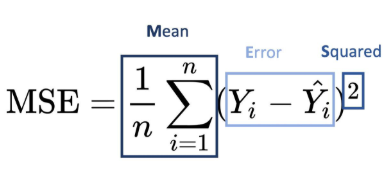

In [19]:
modelo = xgb.XGBRegressor(objective="reg:squarederror", enable_categorical=True, n_estimators=100)

modelo.fit(X_treino, y_treino)
preds = modelo.predict(X_teste)

In [24]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_teste, preds)
print(f"MSE: {mse:.2f}")

MSE: 10342844.00


In [23]:
from sklearn.metrics import root_mean_squared_error

rmse = root_mean_squared_error(y_teste, preds)
print(f"RMSE: {rmse:.2f}")

RMSE: 3216.03


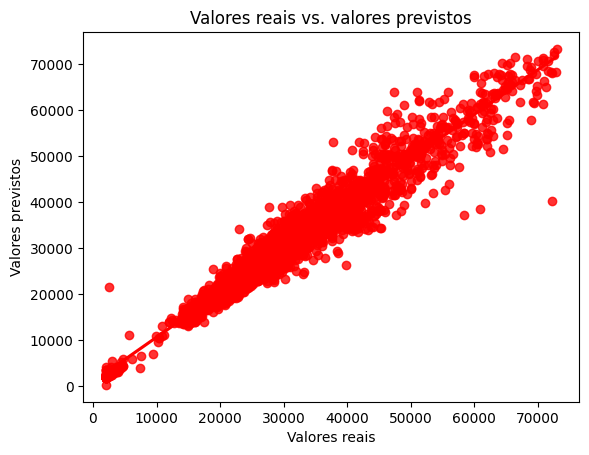

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.regplot(x=y_teste, y=preds, ci=None, color='red')
plt.xlabel("Valores reais")
plt.ylabel("Valores previstos")
plt.title("Valores reais vs. valores previstos")
plt.show()


In [27]:
dtreino = xgb.DMatrix(X_treino, y_treino, enable_categorical=True)
dteste = xgb.DMatrix(X_teste, y_teste, enable_categorical = True)

In [28]:
params = {
    'objective': 'reg:squarederror',
}

modelo = xgb.train(
    params=params,
    dtrain=dtreino,
    num_boost_round=100, evals=[(dteste, 'teste')]
    )

preds = modelo.predict(dteste)

[0]	teste-rmse:11428.38371
[1]	teste-rmse:8533.42009
[2]	teste-rmse:6624.15719
[3]	teste-rmse:5317.96272
[4]	teste-rmse:4528.64846
[5]	teste-rmse:4021.65916
[6]	teste-rmse:3668.05168
[7]	teste-rmse:3450.94346
[8]	teste-rmse:3335.47513
[9]	teste-rmse:3242.19599
[10]	teste-rmse:3193.58783
[11]	teste-rmse:3157.73498
[12]	teste-rmse:3120.63815
[13]	teste-rmse:3106.69788
[14]	teste-rmse:3106.12245
[15]	teste-rmse:3090.39661
[16]	teste-rmse:3088.12342
[17]	teste-rmse:3096.83628
[18]	teste-rmse:3089.25345
[19]	teste-rmse:3088.39562
[20]	teste-rmse:3086.26833
[21]	teste-rmse:3096.15476
[22]	teste-rmse:3096.46501
[23]	teste-rmse:3098.14795
[24]	teste-rmse:3101.39894
[25]	teste-rmse:3103.69448
[26]	teste-rmse:3101.49319
[27]	teste-rmse:3101.81173
[28]	teste-rmse:3104.39488
[29]	teste-rmse:3104.27230
[30]	teste-rmse:3110.42368
[31]	teste-rmse:3111.61856
[32]	teste-rmse:3120.80566
[33]	teste-rmse:3122.50070
[34]	teste-rmse:3122.34627
[35]	teste-rmse:3121.21946
[36]	teste-rmse:3125.90914
[37]	teste

In [30]:
rmse = root_mean_squared_error(dteste.get_label(), preds)
print(f"RMSE: {rmse:.2f}")

RMSE: 3216.03


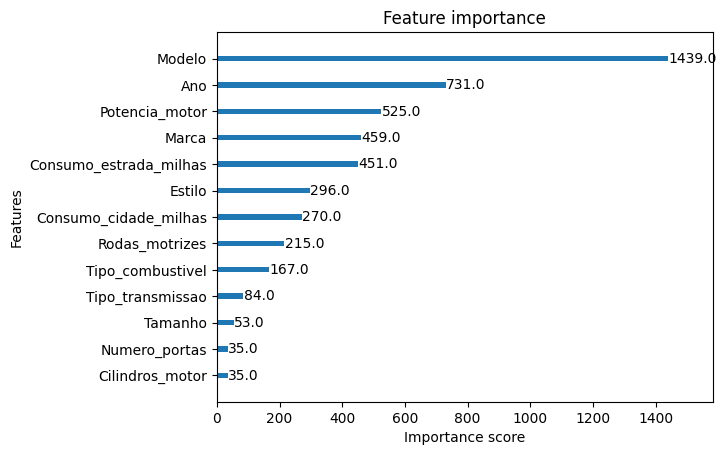

In [32]:
xgb.plot_importance(modelo)
plt.grid(False)
plt.show()